# TTA, ансамбли и потенциал специалистов

Здесь собраны сравнения моделей, TTA и ансамблей, а также **аудит потенциального** каскада специалистов. Специалисты не обучены: oracle/ceiling не является их измеренным качеством.

Начальные настройки PRIMARY/OTHER относятся к историческому сравнению ResNet50. В конце — завершённое сравнение с ResNet101. Обучение и test не запускаются. RUN_SUITE=False читает сохранённые результаты; True запускает только val inference и требует нового INFERENCE_RUN_ID.

Ошибки и неуверенность отдельной модели теперь анализируются в `05_error_analysis.ipynb`. Текущие выводы: `docs/resnet101_review.md`.


In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "error_analysis.py").exists():
    raise RuntimeError("Откройте ноутбук из корня проекта или notebooks/")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.error_analysis import (
    load_predictions, model_comparison, class_metrics, confusion_pairs,
    plot_confusion, show_errors, show_train_examples, image_gallery,
    paired_comparison, specialist_routing_audit,
)
RAW_DIR = PROJECT_ROOT / "data" / "raw"


In [ ]:
EXPERIMENTS = [
    "resnet50_partial_control_001", "resnet50_full_001",
    "resnet50_partial_domain_shift_001",
    "resnet50_partial_domain_shift_stronger_001",
]
PRIMARY = "resnet50_partial_domain_shift_stronger_001"
OTHER = "resnet50_partial_domain_shift_001"
if PRIMARY not in EXPERIMENTS or OTHER not in EXPERIMENTS:
    raise ValueError("PRIMARY и OTHER должны входить в EXPERIMENTS")
frame, classes = load_predictions(PROJECT_ROOT, EXPERIMENTS)
names = classes.set_index("label").class_name.to_dict()
display(model_comparison(frame, EXPERIMENTS).round(3))
print(f"Проверены {len(frame)} уникальных val IDs и raw ground truth.")


## Взаимодополнение моделей

Oracle использует известную разметку и **не является ансамблем**. Реальные soft ensembles ниже используют сохранённые полные probabilities.


,value
both_correct,666.000
both_wrong,18.000
primary_only_correct,9.000
other_only_correct,6.000
different_predictions,17.000
oracle_accuracy_pct_NOT_ensemble,97.425


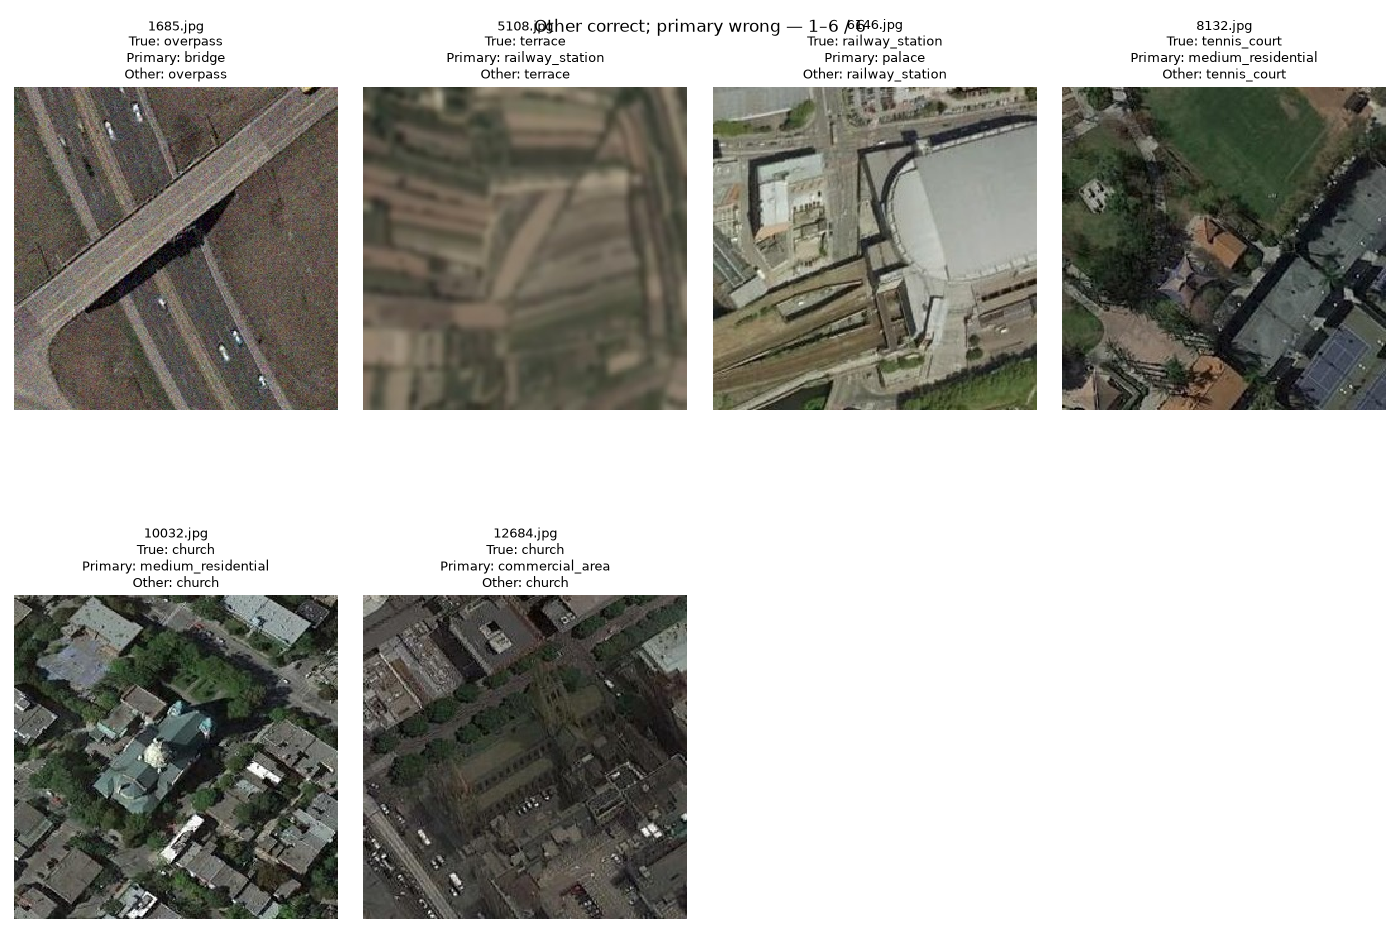

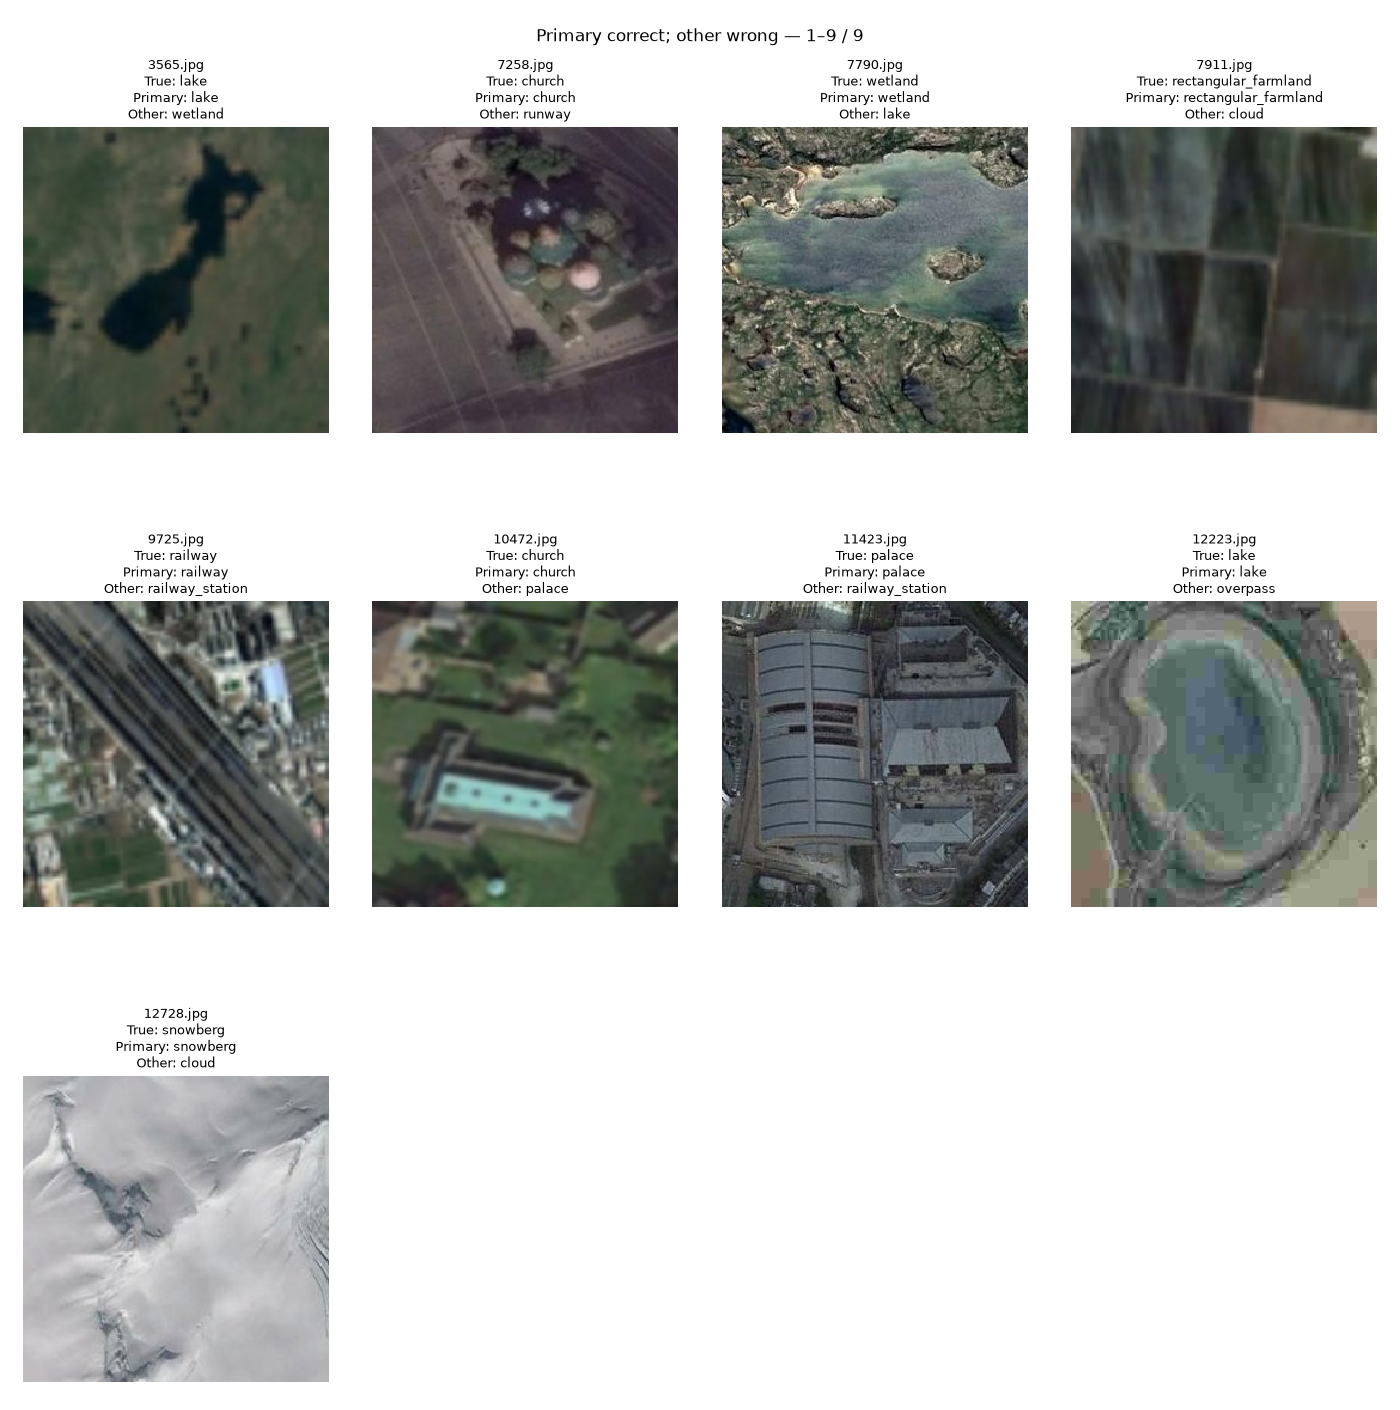

In [8]:
display(paired_comparison(frame, PRIMARY, OTHER).to_frame("value").round(3))
primary_ok = frame[PRIMARY].eq(frame.true_label)
other_ok = frame[OTHER].eq(frame.true_label)
for mask, title in [
    (~primary_ok & other_ok, "Other correct; primary wrong"),
    (primary_ok & ~other_ok, "Primary correct; other wrong"),
]:
    rows = [
        (image_id, f"True: {names[row.true_label]}\nPrimary: {names[row[PRIMARY]]}\nOther: {names[row[OTHER]]}")
        for image_id, row in frame.loc[mask].iterrows()
    ]
    image_gallery(rows, RAW_DIR / "val", title)


## Потенциал и ограничения каскада специалистов

Маршрут определяет **предсказанный** класс. Ground truth используется только для аудита. Оцениваем ошибки внутри группы, правильные ответы под риском изменения, посторонние снимки (нужен reject/other), ошибки, не доходящие до специалиста.

Church → medium_residential не попадёт специалисту church/palace/commercial_area. Поэтому жёсткая маршрутизация по argmax может упустить нужные снимки; после появления probabilities полезнее мягкое объединение или маршрут по top-2.

In [9]:
GROUPS = {
    "buildings": ["church", "palace", "commercial_area"],
    "water": ["lake", "wetland"],
    "courts": ["basketball_court", "tennis_court"],
}
routing = specialist_routing_audit(frame, PRIMARY, classes, GROUPS)
display(routing)
fixable = int(routing.within_group_errors_potentially_fixable.sum())
current_correct = int(primary_ok.sum())
print(f"Внутри групп потенциально исправимы {fixable} / {int((~primary_ok).sum())} ошибок.")
print(f"Идеальный ceiling без ухудшений: {(current_correct + fixable) / len(frame):.2%}.")
print("Это НЕ качество реальных специалистов: они тоже ошибаются и могут портить правильные ответы.")


,routed_images,correct_answers_at_risk,within_group_errors_potentially_fixable,outside_group_images_need_reject,group_errors_missed_by_route
group,,,,,
buildings,106,96,8,2,1
water,69,66,3,0,1
courts,67,65,2,0,3


Внутри групп потенциально исправимы 13 / 24 ошибок.
Идеальный ceiling без ухудшений: 98.43%.
Это НЕ качество реальных специалистов: они тоже ошибаются и могут портить правильные ответы.


## Реальные TTA и ансамбль сохранённых checkpoints

Исторический quality_inference_001 уже выполнен. По умолчанию читаем его результаты. Для нового сравнения с ResNet101 включите её checkpoint, выберите новый ID и RUN_SUITE=True. Suite вычисляет none/flips/D4 и равновесные ансамбли, разделяя forwards. Обучение и test не запускаются; experiments.csv не меняется.


In [10]:
import json
import pandas as pd
from src.inference import run_validation_suite
from src.training.predict import load_probabilities

CHECKPOINTS = {
    "stronger": "artifacts/models/resnet50_partial_domain_shift_stronger_001/best.pt",
    "mild": "artifacts/models/resnet50_partial_domain_shift_001/best.pt",
    # "resnet101": "artifacts/models/resnet101_partial_domain_shift_stronger_001/best.pt",
}
INFERENCE_RUN_ID = "quality_inference_001"
RUN_SUITE = False  # True после добавления новой модели; задайте НОВЫЙ ID
if RUN_SUITE:
    run_validation_suite(CHECKPOINTS, INFERENCE_RUN_ID, project_root=PROJECT_ROOT,
                         device="auto", raw_dir=RAW_DIR, batch_size=16,
                         tta_modes=("none", "flips", "d4"), cache_from="quality_inference_001")
INFERENCE_LOGS = PROJECT_ROOT / "artifacts/logs" / INFERENCE_RUN_ID
INFERENCE_PREDS = PROJECT_ROOT / "artifacts/predictions" / INFERENCE_RUN_ID
if not (INFERENCE_LOGS / "selection.json").exists():
    raise FileNotFoundError("Сначала выполните suite с доступными checkpoints")
comparison = pd.read_csv(INFERENCE_LOGS / "comparison.csv")
selection = json.loads((INFERENCE_LOGS / "selection.json").read_text(encoding="utf-8"))
display(comparison)
print("Выбранный рецепт:", selection["recipe"])


,recipe,correct,errors,val_accuracy,val_nll,models,forward_views_per_image
0,ensemble__flips,677,22,0.968526,0.154461,2,8
1,ensemble__d4,676,23,0.967096,0.153678,2,16
2,ensemble__none,676,23,0.967096,0.168559,2,2
3,mild__d4,675,24,0.965665,0.172576,1,8
4,stronger__none,675,24,0.965665,0.184112,1,1
5,stronger__flips,674,25,0.964235,0.167235,1,4
6,mild__flips,673,26,0.962804,0.183267,1,4
7,mild__none,672,27,0.961373,0.208116,1,1
8,stronger__d4,671,28,0.959943,0.167530,1,8


Выбранный рецепт: ensemble__flips


,class_name,support,errors,false_positives,recall_pct,precision_pct,f1_pct
0,church,35,9,2,74.29,92.86,82.54
1,lake,35,4,0,88.57,100.00,93.94
2,basketball_court,35,3,0,91.43,100.00,95.52
3,terrace,35,2,1,94.29,97.06,95.65
4,baseball_diamond,35,1,0,97.14,100.00,98.55
5,commercial_area,35,1,2,97.14,94.44,95.77
6,railway_station,35,1,0,97.14,100.00,98.55
7,tennis_court,35,1,2,97.14,94.44,95.77
8,bridge,34,0,1,100.00,97.14,98.55
9,cloud,35,0,0,100.00,100.00,100.00


,true_class,predicted_class,count
0,church,palace,5
1,lake,wetland,3
2,basketball_court,tennis_court,2
3,church,commercial_area,2
4,terrace,rectangular_farmland,2
5,baseball_diamond,bridge,1
6,basketball_court,terrace,1
7,church,medium_residential,1
8,church,runway,1
9,commercial_area,church,1


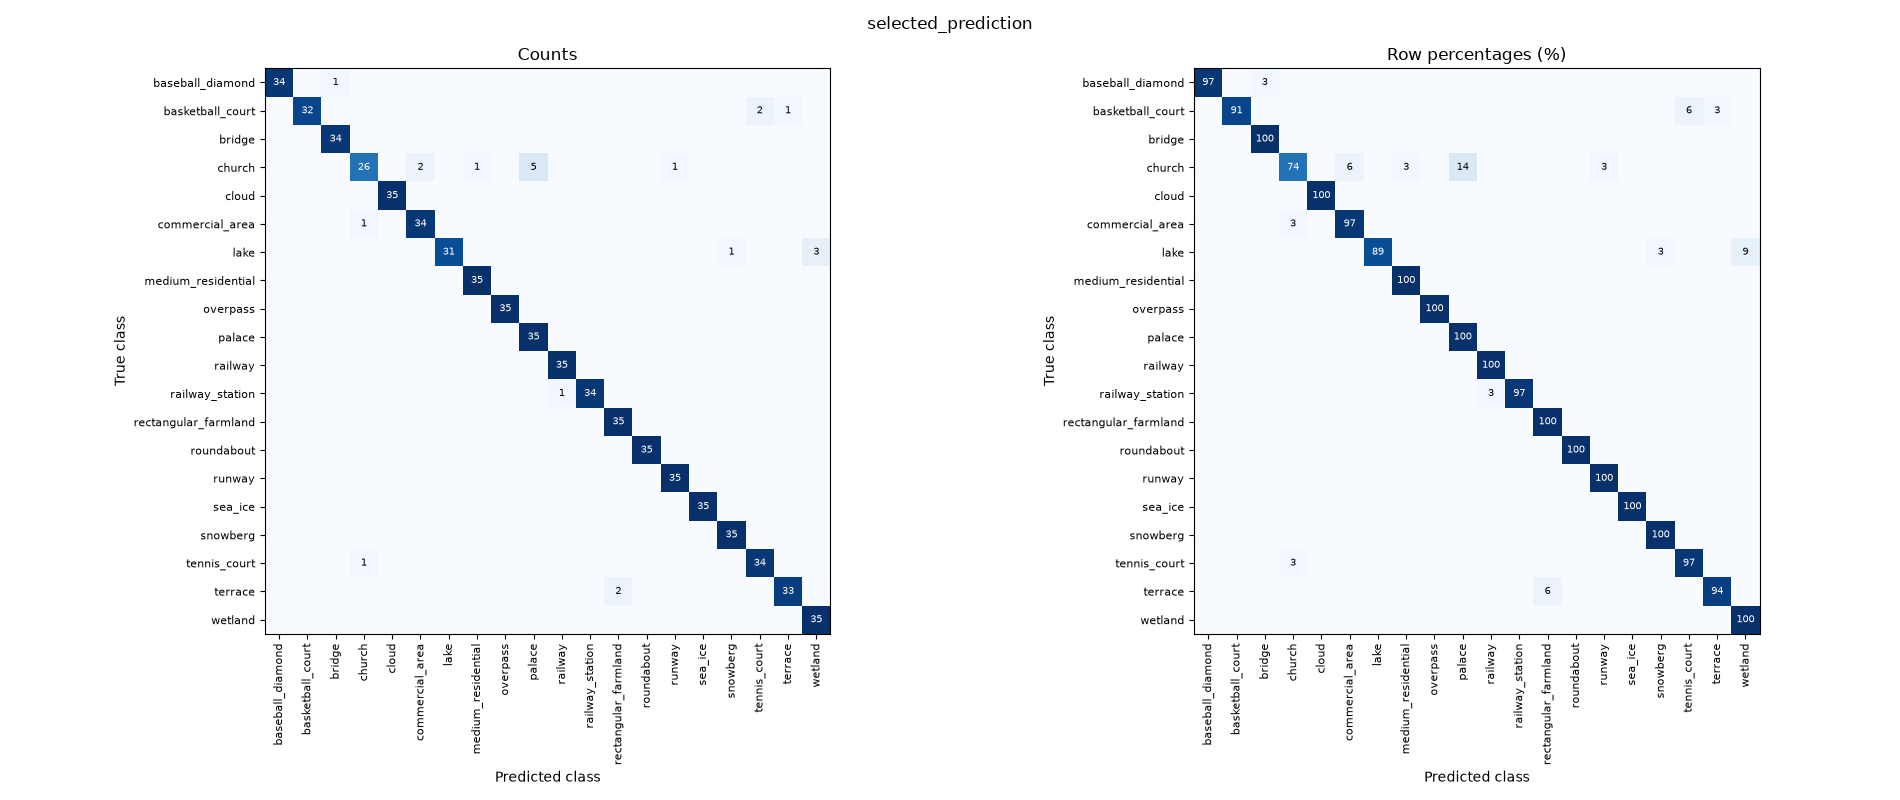

,id,label,true_label,confidence,second_label,margin,entropy
535,10647.jpg,9,3,0.999999,3,0.999997,0.000023
611,12301.jpg,16,6,0.999821,18,0.999642,0.001729
610,12286.jpg,2,0,0.998485,14,0.997873,0.013708
179,3617.jpg,9,3,0.997634,3,0.995275,0.016714
214,4329.jpg,5,3,0.991279,3,0.984115,0.054290
674,13473.jpg,19,6,0.990293,6,0.980760,0.055716
643,12850.jpg,9,3,0.988666,3,0.977377,0.062359
346,6931.jpg,17,1,0.960322,1,0.924093,0.178695
654,13048.jpg,19,6,0.947694,6,0.895389,0.205258
492,10003.jpg,18,1,0.893681,14,0.833609,0.477680


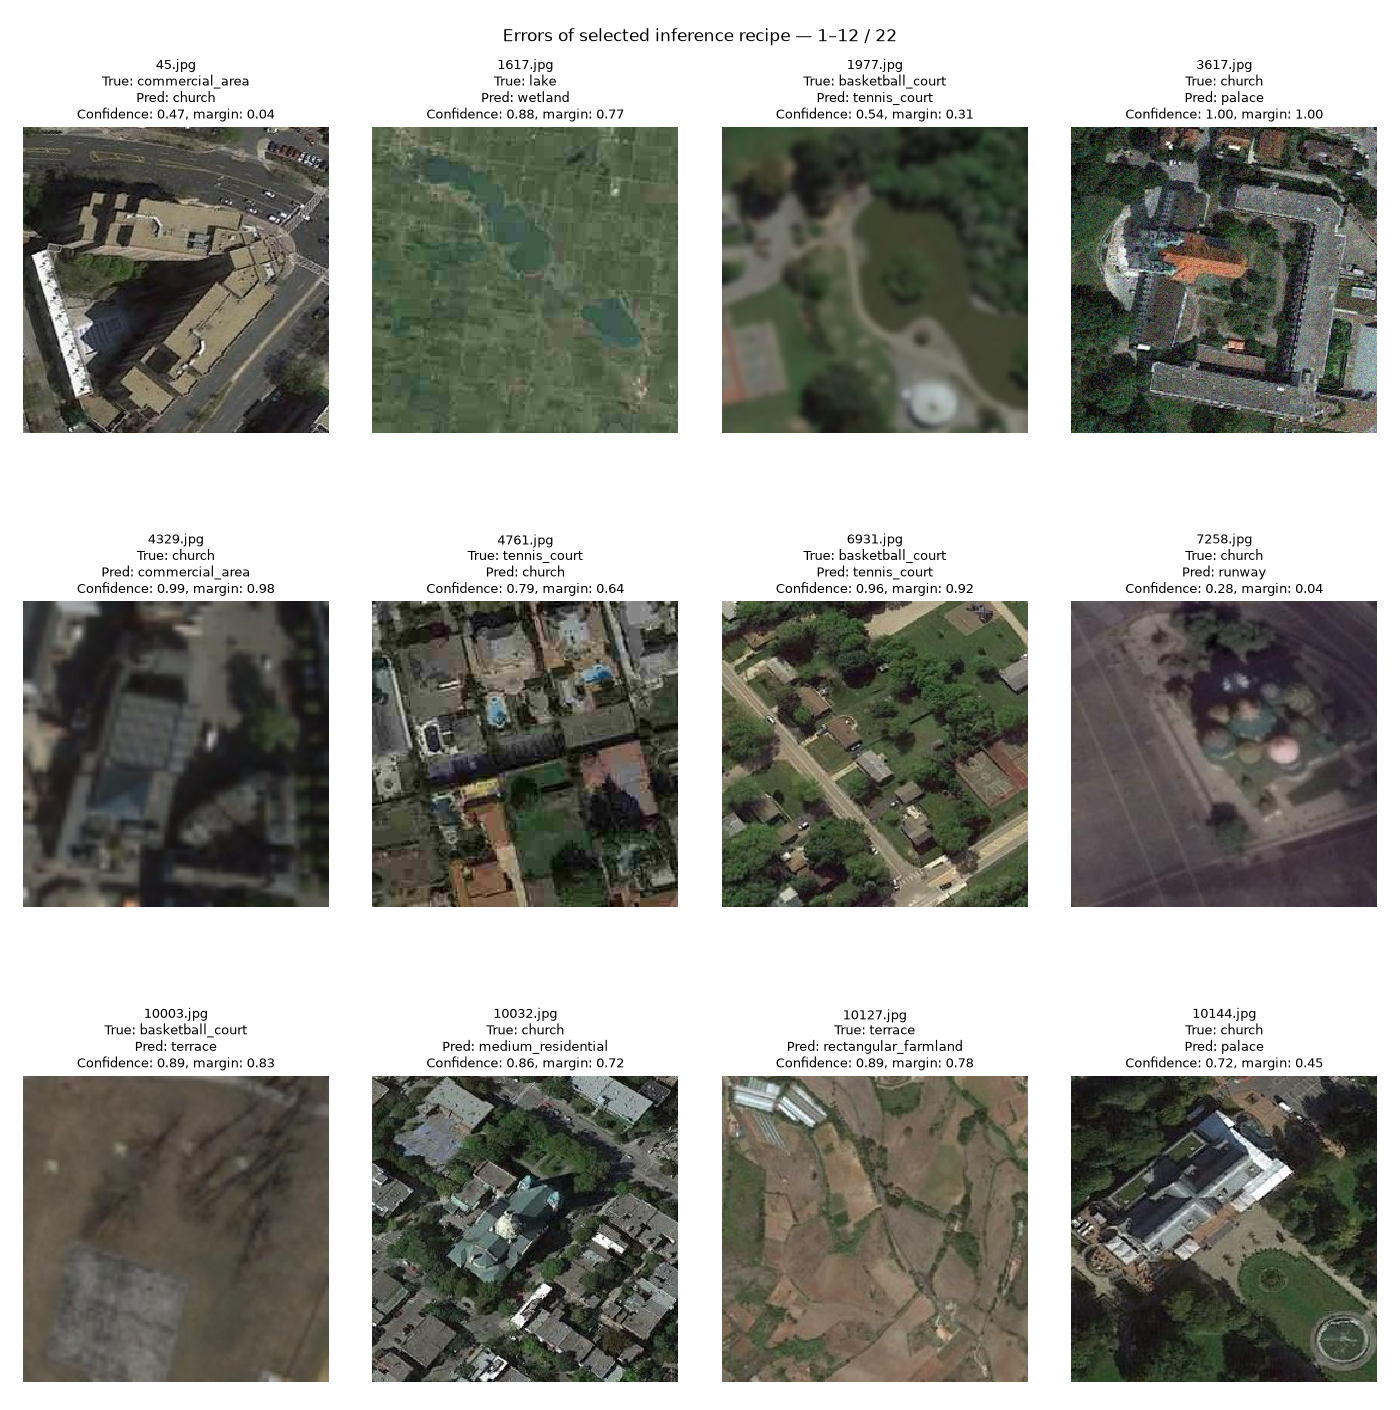

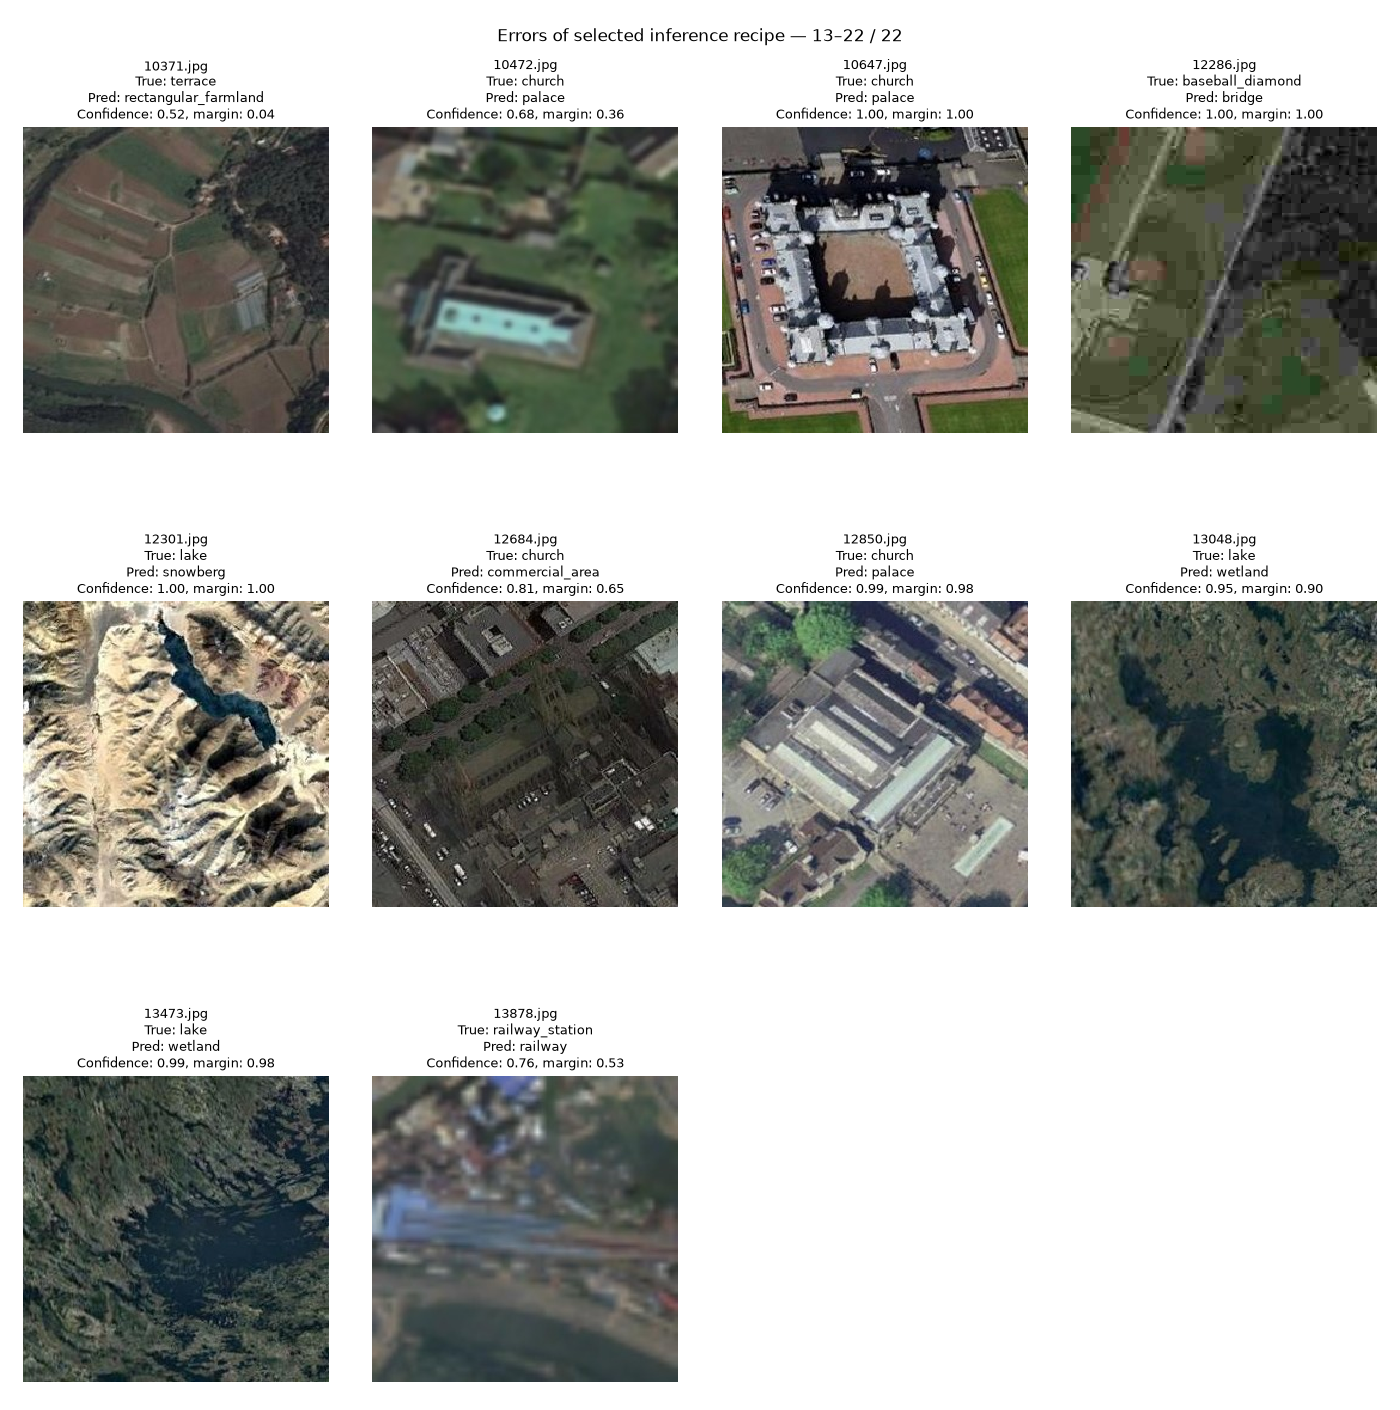

In [11]:
selected_probs = load_probabilities(INFERENCE_PREDS / f"{selection['recipe']}.npz")
scored = selected_probs.table(include_scores=True)
analysis_frame = scored.set_index("id").rename(columns={"label": "selected_prediction"})
display(class_metrics(analysis_frame, "selected_prediction", classes).round(2))
display(confusion_pairs(analysis_frame, "selected_prediction", classes))
plot_confusion(analysis_frame, "selected_prediction", classes)
wrong = scored.loc[scored.label.ne(scored.true_label)]
display(wrong.sort_values("confidence", ascending=False))
image_gallery([
    (r.id, f"True: {names[r.true_label]}\nPred: {names[r.label]}\nConfidence: {r.confidence:.2f}, margin: {r.margin:.2f}")
    for r in wrong.itertuples()
], RAW_DIR / "val", "Errors of selected inference recipe")


In [12]:
baseline = load_probabilities(INFERENCE_PREDS / "stronger__none.npz").table().set_index("id")
selected = scored.set_index("id").loc[baseline.index]
baseline_ok = baseline.label.eq(baseline.true_label)
selected_ok = selected.label.eq(selected.true_label)
print("Исправлено ошибок stronger:", int((~baseline_ok & selected_ok).sum()))
print("Добавлено новых ошибок:", int((baseline_ok & ~selected_ok).sum()))
display(selected.loc[baseline_ok & ~selected_ok])


,label,true_label,confidence,second_label,margin,entropy
id,,,,,,
7258.jpg,14,3,0.280015,9,0.042083,1.720738
10371.jpg,12,18,0.520215,18,0.040443,0.692487
10472.jpg,9,3,0.678349,3,0.358270,0.638918


Исправлено ошибок stronger: 5
Добавлено новых ошибок: 3


Рецепт в selection.json выбран по val Accuracy, затем по NLL и числу views при совпадении метрик. Это наблюдаемое качество на той же val; уверенность softmax не является доказательством правильности разметки. 99_final_pipeline.ipynb воспроизводит фиксированный manifest; test inference там включается отдельно.


## ResNet101: завершённый запуск и сравнение сохранённых probabilities
Исходный запуск: `resnet101_partial_domain_shift_stronger_001`. Ниже нет обучения, новых forward-pass или чтения test. ResNet101 использует **none**, ResNet50 — ранее рассчитанные TTA. См. `docs/resnet101_review.md`.


In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

review_root = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "experiments.csv").is_file())
review = json.loads((review_root / "docs/resnet101_review_audit.json").read_text(encoding="utf-8"))
display(pd.DataFrame(review["comparison"]).drop(columns="members"))
display(pd.DataFrame(review["class_metrics"]["resnet101_none"]).query("errors > 0").sort_values("errors", ascending=False))
display(pd.DataFrame(review["resnet101_errors"]))
display(Image(filename=str(review_root / "docs/resnet101_errors.png")))
